# Dropout regularization: learning curves and baseline comparison

Analyze the completed small, medium, and large runs with dropout **0.2**, and compare each size against its own dropout **0.1** baseline. No GPU is required: this notebook reads downloaded CSV/JSON files and uses NumPy, pandas, and Matplotlib.

Run cells in order. Figures display inline and export as PNG/PDF to `plots/maestro-dropout02-20261106-v1/`. Baseline results and plots remain unchanged. Lower cross-entropy is better. These are fixed-time, single-seed comparisons, not significance tests.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline

# Locate the repository from a kernel started in its root or a subdirectory.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'modified-nanoGPT').is_dir() and (p / 'results').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Start this notebook from the project directory.')

RUN_NAME = 'maestro-dropout02-20261106-v1'
RUN_DIR = ROOT / 'results' / RUN_NAME
PLOT_DIR = ROOT / 'plots' / RUN_NAME
PLOT_DIR.mkdir(parents=True, exist_ok=True)

COLORS = {'small': '#0072B2', 'medium': '#D55E00', 'large': '#009E73'}
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'pdf.fonttype': 42})
print('Read metrics from:', RUN_DIR)
print('Save figures to:', PLOT_DIR)

Read metrics from: /Users/chloeheh/Documents/DSA4212/DSA4212-project/results/maestro-dropout02-20261106-v1
Save figures to: /Users/chloeheh/Documents/DSA4212/DSA4212-project/plots/maestro-dropout02-20261106-v1


## Load the recorded checkpoints

Each `metrics.csv` row is an evaluation on fixed train/validation windows, with dropout disabled. Loss is next-token cross-entropy in nats/token; lower is better. The first row is the untrained model. Subsequent points were recorded approximately every ten minutes. Lines only connect these measurements; they are not additional observations.

In [2]:
metrics = {}
frames = []
for size in COLORS:
    path = RUN_DIR / size / 'metrics.csv'
    frame = pd.read_csv(path)
    required = ['elapsed_seconds', 'step', 'tokens_seen', 'train_loss', 'val_loss']
    if frame.empty or not np.isfinite(frame[required].to_numpy(dtype=float)).all():
        raise ValueError(f'Empty or non-finite metrics: {path}')
    if not frame['elapsed_seconds'].is_monotonic_increasing:
        raise ValueError(f'Checkpoints are not ordered by time: {path}')
    frame['minutes'] = frame['elapsed_seconds'] / 60
    metrics[size] = {column: frame[column].to_numpy() for column in frame.columns}
    frames.append(frame.assign(model=size))

checkpoints = pd.concat(frames, ignore_index=True)
display(checkpoints[['model', 'step', 'minutes', 'train_loss', 'val_loss']].round(4))

,model,step,minutes,train_loss,val_loss
0,small,0,0.0085,5.9357,5.9365
1,small,10532,10.0124,1.8678,1.9450
2,small,21057,20.0173,1.7693,1.8661
3,small,31581,30.0230,1.7309,1.8344
4,small,42101,40.0286,1.7083,1.8213
5,small,52625,50.0339,1.6873,1.8052
6,small,63158,60.0396,1.6733,1.7958
7,small,73698,70.0450,1.6636,1.7891
8,small,84236,80.0505,1.6490,1.7832
9,small,94774,90.0557,1.6411,1.7760


## Summarize best checkpoints

The best checkpoint is selected using validation loss, not training loss. The generalization gap below is final validation loss minus final training loss. These are sampled evaluation losses, not averages over the entire splits.

In [3]:
rows = []
for size, data in metrics.items():
    best = int(np.argmin(data['val_loss']))
    rows.append({
        'model': size,
        'best_step': int(data['step'][best]),
        'best_minutes': data['minutes'][best],
        'tokens_at_best': int(data['tokens_seen'][best]),
        'best_val_loss': data['val_loss'][best],
        'best_val_perplexity': np.exp(data['val_loss'][best]),
        'final_train_loss': data['train_loss'][-1],
        'final_val_loss': data['val_loss'][-1],
        'final_generalization_gap': data['val_loss'][-1] - data['train_loss'][-1],
        'val_increase_from_best': data['val_loss'][-1] - data['val_loss'][best],
    })
summary = pd.DataFrame(rows)
summary.to_csv(PLOT_DIR / 'checkpoint_summary.csv', index=False)
display(summary.round(4))

,model,best_step,best_minutes,tokens_at_best,best_val_loss,best_val_perplexity,final_train_loss,final_val_loss,final_generalization_gap,val_increase_from_best
0,small,126316,120.0022,4139122688,1.7665,5.8505,1.6221,1.7665,0.1444,0.0000
1,medium,20323,60.1366,665944064,1.7872,5.9730,1.4210,1.8051,0.3841,0.0179
2,large,7774,60.4212,254738432,1.7968,6.0305,1.3733,1.8305,0.4572,0.0337


## Training and validation curves for each model

The top row includes initialization. The bottom row omits initialization and uses a shared zoomed y-axis to reveal later progress. Stars mark the best recorded validation checkpoints. PNG and PDF copies are saved when the plotting cell runs.

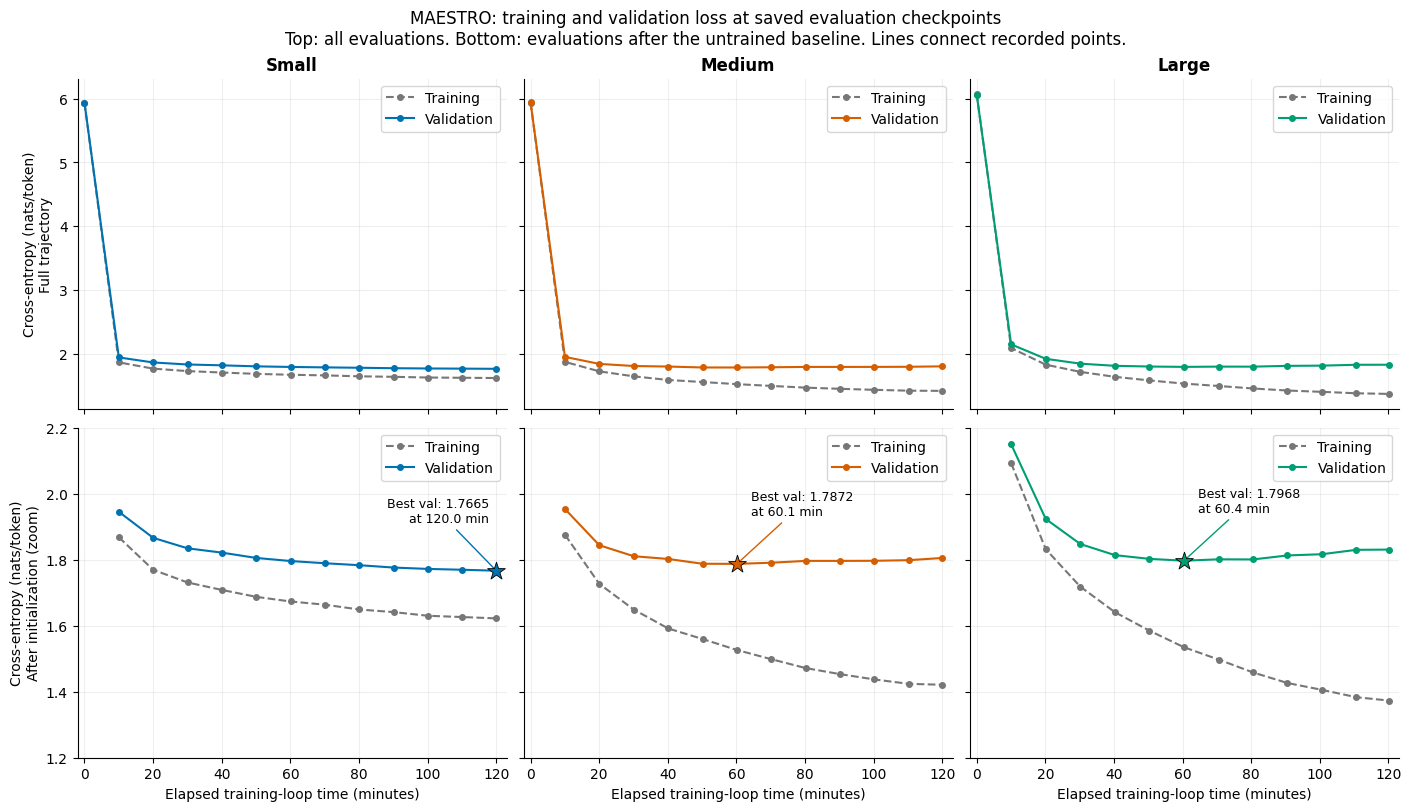

In [4]:
def save_figure(fig, name):
    for extension in ('png', 'pdf'):
        fig.savefig(PLOT_DIR / f'{name}.{extension}', dpi=200, bbox_inches='tight')

fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey='row', layout='constrained')
for column, (size, data) in enumerate(metrics.items()):
    for row in (0, 1):
        ax = axes[row, column]
        include = np.ones(len(data['step']), dtype=bool) if row == 0 else data['step'] > 0
        ax.plot(data['minutes'][include], data['train_loss'][include], 'o--',
                color='#777777', label='Training', markersize=4)
        ax.plot(data['minutes'][include], data['val_loss'][include], 'o-',
                color=COLORS[size], label='Validation', markersize=4)
        ax.grid(alpha=0.2)
        ax.set_xlim(-2, 123)
        ax.set_xticks(np.arange(0, 121, 20))
        ax.legend(loc='upper right')
    axes[0, column].set_title(size.capitalize(), fontweight='bold')
    axes[1, column].set_xlabel('Elapsed training-loop time (minutes)')
    best = int(np.argmin(data['val_loss']))
    ax = axes[1, column]
    ax.scatter(data['minutes'][best], data['val_loss'][best], marker='*', s=180,
               color=COLORS[size], edgecolors='black', linewidths=0.6, zorder=5)
    ax.annotate(f"Best val: {data['val_loss'][best]:.4f}\nat {data['minutes'][best]:.1f} min",
                xy=(data['minutes'][best], data['val_loss'][best]),
                xytext=(-5 if size == 'small' else 10, 35), textcoords='offset points',
                ha='right' if size == 'small' else 'left', fontsize=9,
                arrowprops={'arrowstyle': '-', 'color': COLORS[size]})
axes[0, 0].set_ylabel('Cross-entropy (nats/token)\nFull trajectory')
axes[1, 0].set_ylabel('Cross-entropy (nats/token)\nAfter initialization (zoom)')
axes[1, 0].set_ylim(1.2, 2.2)
fig.suptitle('MAESTRO: training and validation loss at saved evaluation checkpoints\n'
             'Top: all evaluations. Bottom: evaluations after the untrained baseline. '
             'Lines connect recorded points.', fontsize=12)
save_figure(fig, 'learning_curves')
plt.show()
plt.close(fig)

## Compare validation progress across sizes

The following figure overlays validation losses after initialization. All sizes use identical evaluation windows, but they process different numbers of training tokens within the two-hour budget.

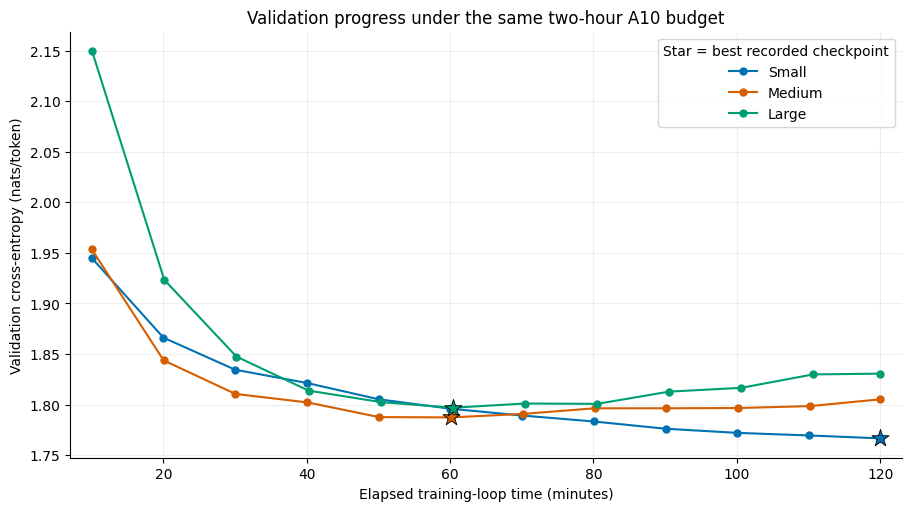

In [5]:
fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
for size, data in metrics.items():
    keep = data['step'] > 0
    ax.plot(data['minutes'][keep], data['val_loss'][keep], 'o-', color=COLORS[size],
            label=size.capitalize(), markersize=5)
    best = int(np.argmin(data['val_loss']))
    ax.scatter(data['minutes'][best], data['val_loss'][best], marker='*', s=170,
               color=COLORS[size], edgecolors='black', linewidths=0.6, zorder=5)
ax.set(xlabel='Elapsed training-loop time (minutes)', ylabel='Validation cross-entropy (nats/token)',
       title='Validation progress under the same two-hour A10 budget', xlim=(7, 123))
ax.grid(alpha=0.2)
ax.legend(title='Star = best recorded checkpoint')
save_figure(fig, 'validation_comparison')
plt.show()
plt.close(fig)

## Compare each size with its dropout 0.1 baseline

The primary metric is the lowest recorded validation cross-entropy. Also inspect final validation loss, the final training/validation gap, and token counts. A smaller gap alone is insufficient if validation loss is worse. All evaluations use the same fixed windows. Both conditions use two-hour budgets, but throughput and token exposure may differ.

The curves below omit the untrained checkpoint so later differences are visible. Stars mark the best recorded validation evaluations; lines connect measurements, not interpolated observations.

In [6]:
BASELINE_DIR = ROOT / 'results' / 'maestro-20261104-optimized-v1'
baselines = {}
comparisons = []
for size in COLORS:
    baseline = pd.read_csv(BASELINE_DIR / size / 'metrics.csv')
    baseline['minutes'] = baseline['elapsed_seconds'] / 60
    baselines[size] = baseline
    current = pd.DataFrame(metrics[size])
    best_base = baseline.loc[baseline['val_loss'].idxmin()]
    best_new = current.loc[current['val_loss'].idxmin()]
    last_base, last_new = baseline.iloc[-1], current.iloc[-1]
    comparisons.append({
        'model': size,
        'baseline_best_val': best_base['val_loss'],
        'dropout02_best_val': best_new['val_loss'],
        'best_val_change': best_new['val_loss'] - best_base['val_loss'],
        'best_perplexity_change_pct': 100 * (np.exp(best_new['val_loss'] - best_base['val_loss']) - 1),
        'baseline_best_minutes': best_base['minutes'],
        'dropout02_best_minutes': best_new['minutes'],
        'baseline_final_val': last_base['val_loss'],
        'dropout02_final_val': last_new['val_loss'],
        'baseline_final_gap': last_base['val_loss'] - last_base['train_loss'],
        'dropout02_final_gap': last_new['val_loss'] - last_new['train_loss'],
        'baseline_tokens': int(last_base['tokens_seen']),
        'dropout02_tokens': int(last_new['tokens_seen']),
    })
comparison = pd.DataFrame(comparisons)
comparison.to_csv(PLOT_DIR / 'dropout_baseline_comparison.csv', index=False)
display(comparison.round(4))
print('Negative loss/perplexity changes favor dropout 0.2.')

,model,baseline_best_val,dropout02_best_val,best_val_change,best_perplexity_change_pct,baseline_best_minutes,dropout02_best_minutes,baseline_final_val,dropout02_final_val,baseline_final_gap,dropout02_final_gap,baseline_tokens,dropout02_tokens
0,small,1.7652,1.7665,0.0013,0.1288,110.0902,120.0022,1.7659,1.7665,0.2055,0.1444,4174512128,4139122688
1,medium,1.8018,1.7872,-0.0146,-1.4457,40.0820,60.1366,1.8892,1.8051,0.5593,0.3841,1334280192,1329266688
2,large,1.8122,1.7968,-0.0154,-1.5276,50.2836,60.4212,1.9224,1.8305,0.6360,0.4572,505610240,506560512


Negative loss/perplexity changes favor dropout 0.2.


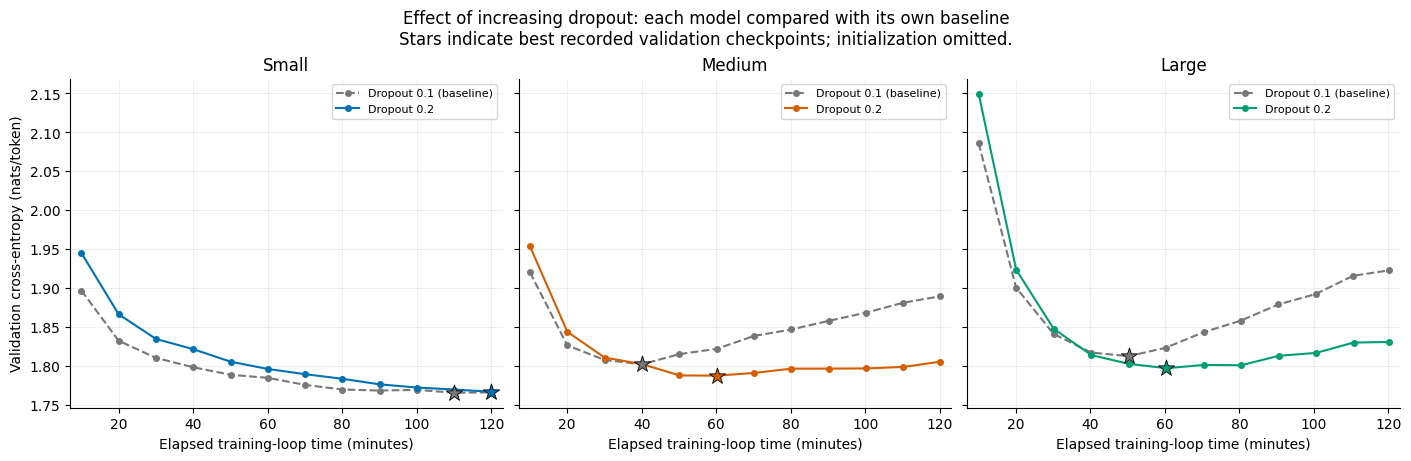

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True, layout='constrained')
for ax, size in zip(axes, COLORS):
    for label, frame, color, style in [
        ('Dropout 0.1 (baseline)', baselines[size], '#777777', '--'),
        ('Dropout 0.2', pd.DataFrame(metrics[size]), COLORS[size], '-'),
    ]:
        later = frame[frame['step'] > 0]
        ax.plot(later['minutes'], later['val_loss'], marker='o', linestyle=style,
                color=color, label=label, markersize=4)
        best = frame.loc[frame['val_loss'].idxmin()]
        ax.scatter(best['minutes'], best['val_loss'], marker='*', s=150,
                   color=color, edgecolors='black', linewidths=0.6, zorder=5)
    ax.set(title=size.capitalize(), xlabel='Elapsed training-loop time (minutes)', xlim=(7, 123))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
axes[0].set_ylabel('Validation cross-entropy (nats/token)')
fig.suptitle('Effect of increasing dropout: each model compared with its own baseline\n'
             'Stars indicate best recorded validation checkpoints; initialization omitted.', fontsize=12)
save_figure(fig, 'dropout_baseline_comparison')
plt.show()
plt.close(fig)

## Read the outcome

The table below summarizes best-validation changes. This describes the observed run only; differences have not been tested across seeds or the full validation split. Checkpoint selection is based on measurements about ten minutes apart. The held-out test split is not evaluated here.

In [8]:
for row in comparison.itertuples():
    direction = 'improved' if row.best_val_change < 0 else 'worsened' if row.best_val_change > 0 else 'matched'
    print(f'{row.model.capitalize()}: best validation loss {direction} '
          f'from {row.baseline_best_val:.4f} to {row.dropout02_best_val:.4f} '
          f'(change {row.best_val_change:+.4f}); '
          f'best recorded at {row.dropout02_best_minutes:.1f} minutes.')
display(pd.DataFrame({'exported_file': [str(p.relative_to(ROOT)) for p in sorted(PLOT_DIR.iterdir()) if p.is_file()]}))

Small: best validation loss worsened from 1.7652 to 1.7665 (change +0.0013); best recorded at 120.0 minutes.
Medium: best validation loss improved from 1.8018 to 1.7872 (change -0.0146); best recorded at 60.1 minutes.
Large: best validation loss improved from 1.8122 to 1.7968 (change -0.0154); best recorded at 60.4 minutes.


,exported_file
0,plots/maestro-dropout02-20261106-v1/checkpoint...
1,plots/maestro-dropout02-20261106-v1/dropout_ba...
2,plots/maestro-dropout02-20261106-v1/dropout_ba...
3,plots/maestro-dropout02-20261106-v1/dropout_ba...
4,plots/maestro-dropout02-20261106-v1/learning_c...
5,plots/maestro-dropout02-20261106-v1/learning_c...
6,plots/maestro-dropout02-20261106-v1/validation...
7,plots/maestro-dropout02-20261106-v1/validation...
